In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [ ]:
data_path = Path("../data/bronze")

In [81]:
# Use a lambda to keep every column EXCEPT the PII ones
customers = pd.read_csv(
    data_path / "customer.csv",
    usecols=lambda column: (
        column not in ["first_name", "last_name", "email", "username", "device_id"]
    ),
)

In [82]:
customers.head()

,customer_id,gender,birthdate,device_type,device_version,home_location_lat,home_location_long,home_location,home_country,first_join_date
0,2870,F,1996-06-14,iOS,iPhone; CPU iPhone OS 14_2_1 like Mac OS X,-1.043345,101.360523,Sumatera Barat,Indonesia,2019-07-21
1,8193,F,1993-08-16,Android,Android 2.2.1,-6.212489,106.818850,Jakarta Raya,Indonesia,2017-07-16
2,7279,M,1989-01-23,iOS,iPad; CPU iPad OS 4_2_1 like Mac OS X,-8.631607,116.428436,Nusa Tenggara Barat,Indonesia,2020-08-23
3,88813,M,1991-01-05,iOS,iPad; CPU iPad OS 14_2 like Mac OS X,1.299332,115.774934,Kalimantan Timur,Indonesia,2021-10-03
4,82542,M,2000-07-15,iOS,iPhone; CPU iPhone OS 10_3_3 like Mac OS X,-2.980807,114.924675,Kalimantan Selatan,Indonesia,2021-04-11


# Focus on customers

In [83]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   customer_id         100000 non-null  int64  
 1   gender              100000 non-null  object 
 2   birthdate           100000 non-null  object 
 3   device_type         100000 non-null  object 
 4   device_version      100000 non-null  object 
 5   home_location_lat   100000 non-null  float64
 6   home_location_long  100000 non-null  float64
 7   home_location       100000 non-null  object 
 8   home_country        100000 non-null  object 
 9   first_join_date     100000 non-null  object 
dtypes: float64(2), int64(1), object(7)
memory usage: 7.6+ MB


In [84]:
customers["birthdate"] = pd.to_datetime(customers["birthdate"])
customers["first_join_date"] = pd.to_datetime(customers["first_join_date"])

cat_cols = ["gender", "device_type", "home_location", "home_country"]
for col in cat_cols:
    customers[col] = customers[col].astype("category")

customers["home_location_lat"] = customers["home_location_lat"].astype("float32")
customers["home_location_long"] = customers["home_location_long"].astype("float32")

In [85]:
customers.head()

,customer_id,gender,birthdate,device_type,device_version,home_location_lat,home_location_long,home_location,home_country,first_join_date
0,2870,F,1996-06-14,iOS,iPhone; CPU iPhone OS 14_2_1 like Mac OS X,-1.043345,101.360519,Sumatera Barat,Indonesia,2019-07-21
1,8193,F,1993-08-16,Android,Android 2.2.1,-6.212489,106.818848,Jakarta Raya,Indonesia,2017-07-16
2,7279,M,1989-01-23,iOS,iPad; CPU iPad OS 4_2_1 like Mac OS X,-8.631607,116.428436,Nusa Tenggara Barat,Indonesia,2020-08-23
3,88813,M,1991-01-05,iOS,iPad; CPU iPad OS 14_2 like Mac OS X,1.299332,115.774933,Kalimantan Timur,Indonesia,2021-10-03
4,82542,M,2000-07-15,iOS,iPhone; CPU iPhone OS 10_3_3 like Mac OS X,-2.980807,114.924675,Kalimantan Selatan,Indonesia,2021-04-11


## Feature ingeneering

In [86]:
ref_date = pd.Timestamp("2022-08-01")  # max date in stream_data

customers["age"] = (ref_date - customers["birthdate"]).dt.days // 365
customers["tenure_days"] = (ref_date - customers["first_join_date"]).dt.days

In [87]:
# Extract major version (e.g., 'Android 10.1' -> 10)
customers["major_os_version"] = (
    customers["device_version"].str.extract("(\d+)").astype("Int64")
)

In [88]:
# Downcast coordinates
customers["home_location_lat"] = customers["home_location_lat"].astype("float32")
customers["home_location_long"] = customers["home_location_long"].astype("float32")

In [89]:
customers.head()

,customer_id,gender,birthdate,device_type,device_version,home_location_lat,home_location_long,home_location,home_country,first_join_date,age,tenure_days,major_os_version
0,2870,F,1996-06-14,iOS,iPhone; CPU iPhone OS 14_2_1 like Mac OS X,-1.043345,101.360519,Sumatera Barat,Indonesia,2019-07-21,26,1107,14
1,8193,F,1993-08-16,Android,Android 2.2.1,-6.212489,106.818848,Jakarta Raya,Indonesia,2017-07-16,28,1842,2
2,7279,M,1989-01-23,iOS,iPad; CPU iPad OS 4_2_1 like Mac OS X,-8.631607,116.428436,Nusa Tenggara Barat,Indonesia,2020-08-23,33,708,4
3,88813,M,1991-01-05,iOS,iPad; CPU iPad OS 14_2 like Mac OS X,1.299332,115.774933,Kalimantan Timur,Indonesia,2021-10-03,31,302,14
4,82542,M,2000-07-15,iOS,iPhone; CPU iPhone OS 10_3_3 like Mac OS X,-2.980807,114.924675,Kalimantan Selatan,Indonesia,2021-04-11,22,477,10


# EDA for cleaning & data quality

In [90]:
# Summary statistics for numeric columns
customers[["age", "tenure_days"]].describe()

,age,tenure_days
count,100000.000000,100000.000000
mean,26.148640,921.850300
std,7.269723,625.103694
min,6.000000,1.000000
25%,21.000000,369.750000
50%,26.000000,821.000000
75%,31.000000,1437.000000
max,68.000000,2223.000000


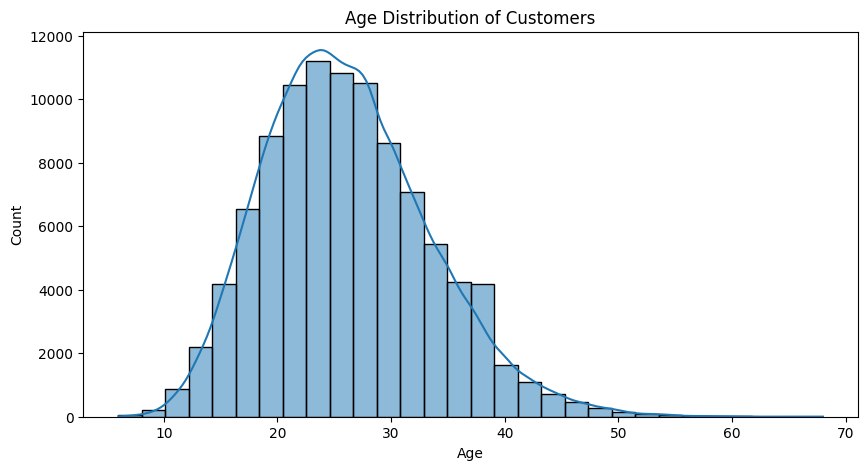

In [91]:
plt.figure(figsize=(10, 5))
sns.histplot(customers["age"], bins=30, kde=True)
plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

In [92]:
initial_count = len(customers)
customers = customers[customers["age"] >= 15].copy()
print(f"Dropped {initial_count - len(customers)} rows with age < 15.")

Dropped 3324 rows with age < 15.


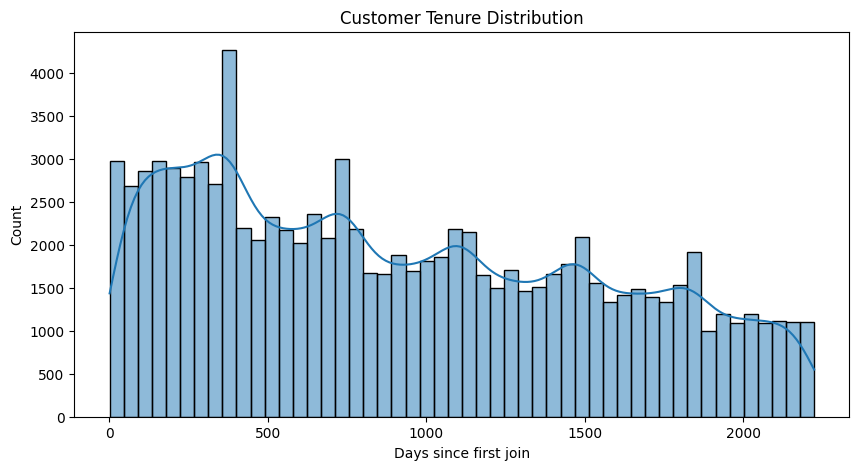

In [95]:
plt.figure(figsize=(10, 5))
sns.histplot(customers["tenure_days"], bins=50, kde=True)
plt.title("Customer Tenure Distribution")
plt.xlabel("Days since first join")
plt.ylabel("Count")
plt.show()

I notice a seasonality in data which indicate something like a big sales each year

In [96]:
# Create cohorts based on the yearly spikes you found
customers["loyalty_tier"] = pd.cut(
    customers["tenure_days"],
    bins=[0, 365, 1095, 3000],
    labels=["New", "Active", "Veteran"],
)

In [101]:
customers.to_parquet(
    "../data/interim/customers_clean.parquet", index=False, engine="fastparquet"
)